---
title: "Newton's Laws — Level 2"
short_title: "01 Newton's Laws"
numbering:
  heading_2: true
  equation: true
---

# Newton's Laws

:::{seealso} Math for this topic
- [M1: Vectors and ODEs](../math/01-vectors-odes.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do with Newton's laws |
|---|---|---|
| 1 | Tipler & Mosca, ch. 4–5 | Draw a free-body diagram, add constant forces, get a number |
| **2** | **Taylor, ch. 1 (plus the drag material that follows it)** | **Write the law as a differential equation and solve it in general, including forces that depend on velocity** |
| 3 | Goldstein, ch. 1 | Handle constraints with generalized coordinates and D'Alembert's principle |

The new skill at this level is treating $\vec{F} = m\ddot{\vec{r}}$ as an ODE whose solution is a function of time, rather than an algebra problem whose answer is one number.
:::

These notes are original explanations, examples and figures written to match the Level 2 rung of the mechanics ladder. They do not reproduce any textbook. Worked examples have solutions in dropdowns. The exercises have a **hint** dropdown and a separate **answer** dropdown, so you can work them before checking.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (7, 4.6),
    "axes.grid": True,
    "grid.alpha": 0.3,
})
g = 9.81  # m/s^2

## Where Newtonian Mechanics Applies

Newton's three laws describe how things move in response to forces. They are extraordinarily accurate inside a well-defined domain and fail outside it.

| Regime | Signal that Newton is failing | What replaces it |
|---|---|---|
| Very fast | speeds approaching $c$; $v/c$ not negligible | special relativity |
| Very small | actions comparable to $\hbar$ (atoms, electrons in solids) | quantum mechanics |
| Very strong gravity | $GM/(rc^2)$ not negligible (near neutron stars, black holes) | general relativity |

A baseball has $v/c \sim 10^{-7}$, and its angular momentum is about $10^{33}\hbar$. Corrections of that size are far below anything you could measure, so classical mechanics is exact for practical purposes.

:::{note} Why this matters at Level 2
Level 1 problems never ask whether the laws apply. At this level you should be able to say *why* a model is valid, for example by estimating $v/c$ or comparing an action to $\hbar$. That habit pays off in astrophysics, where the same object (a star, a gas cloud) can sit in different regimes depending on what you ask.
:::

## Vectors, Frames and Derivatives

A **reference frame** is a choice of origin and axes, plus a clock. The position of a particle relative to the origin is

$$
\vec{r} = x\,\hat{x} + y\,\hat{y} + z\,\hat{z} = \sum_i r_i\,\hat{e}_i ,
$$

and its velocity and acceleration are time derivatives, written with Newton's dot notation:

$$
\vec{v} = \dot{\vec{r}}, \qquad \vec{a} = \dot{\vec{v}} = \ddot{\vec{r}} .
$$

In Cartesian coordinates the unit vectors $\hat{x}, \hat{y}, \hat{z}$ are the same at every point and every time, so differentiating a vector just means differentiating its components:

$$
\dot{\vec{r}} = \dot x\,\hat{x} + \dot y\,\hat{y} + \dot z\,\hat{z} .
$$

That shortcut is **only** valid because the basis vectors are constant. In polar coordinates (later section) the basis vectors move with the particle, and their derivatives add new terms.

The product rules carry over from ordinary calculus, with care about order in the cross product:

$$
\frac{d}{dt}(f\vec{A}) = \dot f\vec{A} + f\dot{\vec{A}}, \qquad
\frac{d}{dt}(\vec{A}\cdot\vec{B}) = \dot{\vec{A}}\cdot\vec{B} + \vec{A}\cdot\dot{\vec{B}}, \qquad
\frac{d}{dt}(\vec{A}\times\vec{B}) = \dot{\vec{A}}\times\vec{B} + \vec{A}\times\dot{\vec{B}} .
$$

:::{important} Index notation
Writing $\vec{r} = \sum_i r_i \hat{e}_i$ with $r_1 = x$, $r_2 = y$, $r_3 = z$ turns many vector identities into one-line sums. For example, $\vec{A}\cdot\vec{B} = \sum_i A_i B_i$. Goldstein uses this notation constantly, so it is worth getting comfortable with it now.
:::

### Exercises

1. Show that $\dfrac{d}{dt}|\vec{r}|^2 = 2\,\vec{r}\cdot\vec{v}$.
2. A particle moves so that its distance from the origin never changes. Show that its velocity is always perpendicular to its position vector.

:::{dropdown} Hints
1. Write $|\vec{r}|^2 = \vec{r}\cdot\vec{r}$ and use the dot-product rule.
2. Use the result of part 1.
:::

:::{dropdown} Answers
1. $\dfrac{d}{dt}(\vec{r}\cdot\vec{r}) = \dot{\vec{r}}\cdot\vec{r} + \vec{r}\cdot\dot{\vec{r}} = 2\,\vec{r}\cdot\vec{v}$.
2. $|\vec{r}|^2$ is constant, so its derivative $2\,\vec{r}\cdot\vec{v}$ is zero. Hence $\vec{r}\perp\vec{v}$. Circular motion is the familiar case.
:::

## Mass and Force

Newton's laws use two quantities, mass and force, that need operational definitions.

**Mass.** Mass measures how hard it is to change an object's velocity. One way to measure it without any idea of force: put two objects on a frictionless track with a compressed spring between them, release the spring, and measure their speeds. Whatever the spring, the ratio of speeds is the same, and we *define*

$$
\frac{m_1}{m_2} = \frac{v_2}{v_1} .
$$

Choosing one standard object as 1 kg then fixes every other mass. (This is really the third law in disguise, as the next sections show.)

**Force.** A force is a push or a pull. Operationally, a calibrated spring stretched by a fixed amount defines a unit of force, and two such springs pulling side by side define two units. The newton is the force that gives 1 kg an acceleration of $1\ \text{m/s}^2$.

:::{note} Inertial versus gravitational mass
Mass also appears in the law of gravity, $F = GMm/r^2$. Nothing in Newton's laws requires the "resistance to acceleration" mass and the "gravitational charge" mass to be equal, yet experiments show they agree to better than one part in $10^{14}$. That equality is the reason all objects fall with the same acceleration, and it became the starting point of general relativity.
:::

### Exercises

1. Two carts sit at rest with a compressed spring between them. When the spring is released, cart A ($2.0$ kg) moves off at $0.60$ m/s and cart B at $0.40$ m/s in the opposite direction. Find the mass of cart B.

:::{dropdown} Hint
Use the definition $m_1/m_2 = v_2/v_1$, with speeds rather than signed velocities.
:::

:::{dropdown} Answer
$m_B = m_A\,v_A/v_B = 2.0 \times 0.60/0.40 = 3.0$ kg.
:::

## The First and Second Laws

:::{prf:definition} First law (inertia)
:label: def-first-law

In the absence of forces, a particle moves with constant velocity.
:::

:::{prf:definition} Second law
:label: def-second-law

For a particle of mass $m$ with momentum $\vec{p} = m\vec{v}$, the net force on it equals the rate of change of its momentum:

$$
\vec{F} = \dot{\vec{p}} .
$$ (eq-second-law)

When $m$ is constant this is $\vec{F} = m\dot{\vec{v}} = m\ddot{\vec{r}}$.
:::

### Inertial frames

The first law looks like a special case of the second (set $\vec{F} = 0$), but it does real work: it tells us **which frames** the laws apply in.

Picture a ball resting on the floor of a train. When the train brakes, the ball rolls forward, although nothing pushed it. In the train's frame the first law fails. In the frame of the ground it holds: the ball just keeps moving at the speed it had while the train slows down beneath it.

:::{prf:definition} Inertial frame
:label: def-inertial

An **inertial frame** is a reference frame in which the first law holds. Newton's laws are valid as stated only in inertial frames.
:::

Any frame moving at constant velocity relative to an inertial frame is also inertial, because a constant velocity added to every particle does not change any acceleration. A frame that accelerates or rotates relative to an inertial frame is **noninertial**.

:::{warning} The Earth is only approximately inertial
The Earth spins once a day and orbits the Sun once a year. The resulting accelerations are small: the centripetal acceleration at the equator is about $0.034\ \text{m/s}^2$, about $0.3\%$ of $g$. For most lab problems the ground counts as inertial. The rotation shows up in long-range artillery, ocean currents, hurricanes and Foucault's pendulum, which are Level 2 and 3 topics on noninertial frames.
:::

### The second law is a differential equation

At Level 1 the force is usually constant, so $\vec{a} = \vec{F}/m$ is a number and the kinematic formulas finish the job. In general the force depends on position, velocity and time, $\vec{F}(\vec{r}, \dot{\vec{r}}, t)$, and the second law becomes

$$
m\ddot{\vec{r}} = \vec{F}(\vec{r}, \dot{\vec{r}}, t) ,
$$ (eq-newton-ode)

a second-order ODE for each component. A unique solution needs initial position **and** initial velocity, six numbers in three dimensions. That fact (two initial conditions per coordinate) is why the state of a classical system is a point in **phase space**, an idea that becomes central in Goldstein.

### Exercises

1. A small mass hangs on a string from the ceiling of a car that accelerates forward at $a$ on level ground. In the ground frame, find the angle the string makes with the vertical.
2. In the car's frame the mass is at rest, yet the string is tilted. Which of Newton's laws appears to fail there, and why?

:::{dropdown} Hints
1. Only two forces act: tension and gravity. The mass shares the car's acceleration.
2. Ask whether the forces you can identify in the car's frame add to zero.
:::

:::{dropdown} Answers
1. Horizontally $T\sin\theta = ma$; vertically $T\cos\theta = mg$. So $\tan\theta = a/g$, with the string tilted backward.
2. The first law (and the second) fail in the car's frame: the real forces, tension and gravity, add to a nonzero horizontal force, yet the mass stays at rest. The car's frame is noninertial. You can rescue the laws there only by adding a fictitious force $-m\vec{a}$.
:::

## The Third Law and Momentum Conservation

:::{prf:definition} Third law
:label: def-third-law

If object 1 exerts a force $\vec{F}_{21}$ on object 2, then object 2 exerts a force $\vec{F}_{12} = -\vec{F}_{21}$ on object 1.
:::

The two forces in a third-law pair always act on **different** objects. That is why they never cancel in a single free-body diagram.

### From the third law to conservation of momentum

Take $N$ particles. Split the force on particle $\alpha$ into the external force $\vec{F}^{\text{ext}}_\alpha$ and the internal forces $\vec{F}_{\alpha\beta}$ from each other particle $\beta$:

$$
\dot{\vec{p}}_\alpha = \vec{F}^{\text{ext}}_\alpha + \sum_{\beta\ne\alpha}\vec{F}_{\alpha\beta} .
$$

Add over all particles to get the rate of change of the total momentum $\vec{P} = \sum_\alpha \vec{p}_\alpha$:

$$
\dot{\vec{P}} = \sum_\alpha \vec{F}^{\text{ext}}_\alpha + \sum_\alpha\sum_{\beta\ne\alpha}\vec{F}_{\alpha\beta} .
$$

The double sum contains every pair twice, as $\vec{F}_{\alpha\beta} + \vec{F}_{\beta\alpha}$, and the third law makes each pair vanish. So

$$
\dot{\vec{P}} = \vec{F}^{\text{ext}} .
$$ (eq-total-momentum)

:::{prf:theorem} Conservation of momentum
:label: thm-momentum

If the net external force on a system is zero, its total momentum is constant.
:::

### Center of mass

Define the **center of mass** $\vec{R} = \frac{1}{M}\sum_\alpha m_\alpha \vec{r}_\alpha$, with $M = \sum_\alpha m_\alpha$. Then $\vec{P} = M\dot{\vec{R}}$, and {eq}`eq-total-momentum` becomes

$$
M\ddot{\vec{R}} = \vec{F}^{\text{ext}} .
$$

The center of mass moves like a single particle carrying all the mass, driven only by external forces. However violently the parts interact, the internal forces cannot move $\vec{R}$.

::::{prf:example} Two masses joined by a spring
:label: ex-spring-pair

Masses $m_1 = 1$ kg and $m_2 = 3$ kg float in space, joined by a spring with $k = 12$ N/m. Initially the spring is at its natural length, $m_1$ is at rest, and $m_2$ moves at $2$ m/s along the line joining them. Describe the motion.

:::{dropdown} Solution
No external force acts, so the center of mass moves at constant velocity:

$$
\dot R = \frac{m_1\cdot 0 + m_2\cdot 2}{m_1+m_2} = 1.5\ \text{m/s}.
$$

Relative to the center of mass, the two masses oscillate. The separation $s = x_2 - x_1$ obeys

$$
\ddot s = \ddot x_2 - \ddot x_1 = -\frac{k(s - \ell)}{m_2} - \frac{k(s-\ell)}{m_1} = -\frac{k}{\mu}(s - \ell), \qquad \mu = \frac{m_1 m_2}{m_1 + m_2} = 0.75\ \text{kg},
$$

so the spring oscillates at $\omega = \sqrt{k/\mu} = 4$ rad/s, period $\approx 1.57$ s. The **reduced mass** $\mu$ appears whenever a two-body problem is split into center-of-mass and relative motion. It returns in central-force orbits.
:::
::::

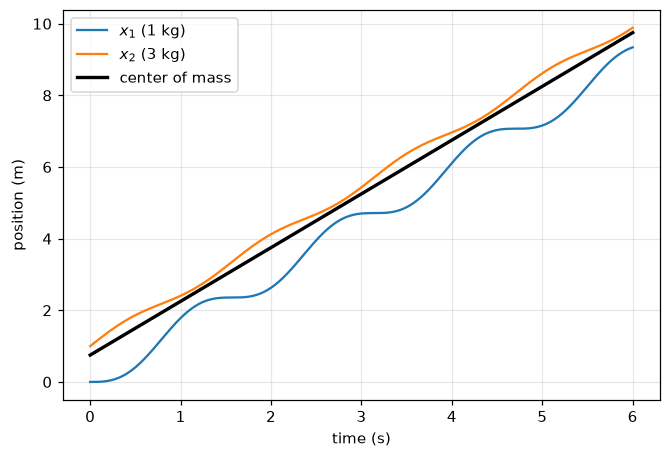

In [2]:
#| label: fig-spring-pair
#| caption: Two masses joined by a spring. Each mass lurches back and forth, but the center of mass (black) moves at a perfectly steady 1.5 m/s.
m1, m2, k, ell = 1.0, 3.0, 12.0, 1.0

def rhs(t, y):
    x1, x2, v1, v2 = y
    f = k * (x2 - x1 - ell)        # spring force on m1 (toward m2 when stretched)
    return [v1, v2, f / m1, -f / m2]

t = np.linspace(0, 6, 600)
sol = solve_ivp(rhs, (0, 6), [0, ell, 0, 2.0], t_eval=t, rtol=1e-9)
x1, x2 = sol.y[0], sol.y[1]
X = (m1 * x1 + m2 * x2) / (m1 + m2)

fig, ax = plt.subplots()
ax.plot(t, x1, label="$x_1$ (1 kg)")
ax.plot(t, x2, label="$x_2$ (3 kg)")
ax.plot(t, X, "k", lw=2.2, label="center of mass")
ax.set_xlabel("time (s)"); ax.set_ylabel("position (m)")
ax.legend(); plt.show()

:::{warning} When the third law fails
The third law holds for contact forces and for gravity and electrostatics between charges at rest. It can fail for **magnetic forces between moving charges**. Two charges moving at right angles to each other exert magnetic forces that are not equal and opposite. Momentum is still conserved, because the electromagnetic field itself carries momentum. In that case "total momentum" must include the field's share. This is one of the places where Level 2 mechanics hands off to Level 2 E&M.
:::

### Exercises

1. An 80 kg astronaut at rest beside a space station throws a 2.0 kg wrench, which leaves at 5.0 m/s relative to the station. Find the astronaut's recoil speed.
2. A firework shell moving on a parabolic arc explodes into many fragments. What path does the center of mass of the fragments follow until the first one lands?

:::{dropdown} Hints
1. Total momentum starts at zero.
2. Which forces in the explosion are internal?
:::

:::{dropdown} Answers
1. $80v = 2.0 \times 5.0$, so $v = 0.125$ m/s, opposite to the wrench.
2. The same parabola the shell was on. The explosion forces are internal, and the only external force (gravity, ignoring drag) has not changed.
:::

## Cartesian Components

Because the Cartesian unit vectors are constant, the vector equation $\vec{F} = m\ddot{\vec{r}}$ splits into three scalar equations:

$$
F_x = m\ddot x, \qquad F_y = m\ddot y, \qquad F_z = m\ddot z .
$$ (eq-cartesian)

When each force component depends only on its own coordinate and velocity, the equations are **uncoupled** and can be solved one at a time. That is why the vacuum projectile is easy: $\ddot x = 0$ and $\ddot y = -g$ have nothing to do with each other. Quadratic air resistance, later in these notes, couples them and forces a numerical solution.

::::{prf:example} A puck pushed by a rotating force
:label: ex-rotating-force

A puck of mass $m$ rests at the origin on a frictionless horizontal table. Starting at $t = 0$, a force of constant magnitude $F_0$ acts on it, with its direction rotating counterclockwise at angular frequency $\omega$:
$\vec{F} = F_0\langle\cos\omega t,\ \sin\omega t\rangle$. Find the velocity and describe the path.

:::{dropdown} Solution
The components separate:

$$
m\dot v_x = F_0\cos\omega t, \qquad m\dot v_y = F_0\sin\omega t .
$$

Integrating from rest,

$$
v_x = \frac{F_0}{m\omega}\sin\omega t, \qquad v_y = \frac{F_0}{m\omega}\,(1 - \cos\omega t) .
$$

The average of $v_x$ over a cycle is zero, but $v_y$ averages $F_0/(m\omega)$. The puck loops repeatedly while drifting steadily in the $+y$ direction, tracing a cycloid. A force that points in every direction equally over a cycle still produces net drift, because the puck starts from rest at a particular phase of the force.
:::
::::

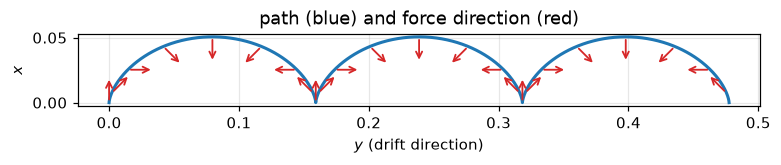

In [3]:
#| label: fig-rotating-force
#| caption: The puck under a rotating force traces a cycloid and drifts in the +y direction at average speed F₀/(mω).
F0, m, w = 1.0, 1.0, 2 * np.pi
t = np.linspace(0, 3, 900)
x = F0 / (m * w**2) * (1 - np.cos(w * t))
y = F0 / (m * w) * t - F0 / (m * w**2) * np.sin(w * t)

# Drawn sideways (y horizontal) so the long drift direction fits a phone screen
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(y, x, lw=2)
for tk in np.arange(0, 3, 0.125):
    xk = F0 / (m * w**2) * (1 - np.cos(w * tk))
    yk = F0 / (m * w) * tk - F0 / (m * w**2) * np.sin(w * tk)
    ax.annotate("", xy=(yk + 0.02 * np.sin(w * tk), xk + 0.02 * np.cos(w * tk)), xytext=(yk, xk),
                arrowprops=dict(arrowstyle="->", color="tab:red", lw=1.2))
ax.set_aspect("equal"); ax.set_xlabel("$y$ (drift direction)"); ax.set_ylabel("$x$")
ax.set_title("path (blue) and force direction (red)")
plt.show()

In [19]:
# Check the velocity and path symbolically
t, m, F0, w = sp.symbols("t m F_0 omega", positive=True)
vx = sp.integrate(F0 * sp.cos(w * t) / m, (t, 0, t))
vy = sp.integrate(F0 * sp.sin(w * t) / m, (t, 0, t))
display(Math(r"v_x = " + sp.latex(vx)))
display(Math(r"v_y = " + sp.latex(vy)))
display(Math(r"\text{average } v_y \text{ over one period} = " + sp.latex(sp.integrate(vy, (t, 0, 2 * sp.pi / w)) / (2 * sp.pi / w))))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. A block slides down a rough incline of angle $\alpha$ with kinetic friction coefficient $\mu$. Choose axes along and perpendicular to the incline and find its acceleration.
2. For what angle does the block slide at constant velocity once started?

:::{dropdown} Hints
1. Perpendicular to the incline there is no acceleration, which fixes the normal force.
2. Set your answer to part 1 equal to zero.
:::

:::{dropdown} Answers
1. $N = mg\cos\alpha$, so $a = g(\sin\alpha - \mu\cos\alpha)$ down the incline.
2. $\tan\alpha = \mu$.
:::

## Plane Polar Coordinates

For motion around a center (orbits, pendulums, anything on a turntable) polar coordinates $(r, \phi)$ are more natural than $(x, y)$. The catch is that the polar unit vectors change direction as the particle moves.

At the particle's location, define

$$
\hat{r} = \langle\cos\phi,\ \sin\phi\rangle \quad \text{(pointing away from the origin)}, \qquad
\hat{\phi} = \langle -\sin\phi,\ \cos\phi\rangle \quad \text{(pointing in the direction of increasing } \phi\text{)}.
$$

Both depend on $\phi$, so they change whenever $\phi$ does. By the chain rule,

$$
\frac{d\hat{r}}{dt} = \dot\phi\,\hat{\phi}, \qquad
\frac{d\hat{\phi}}{dt} = -\dot\phi\,\hat{r} .
$$ (eq-unit-derivs)

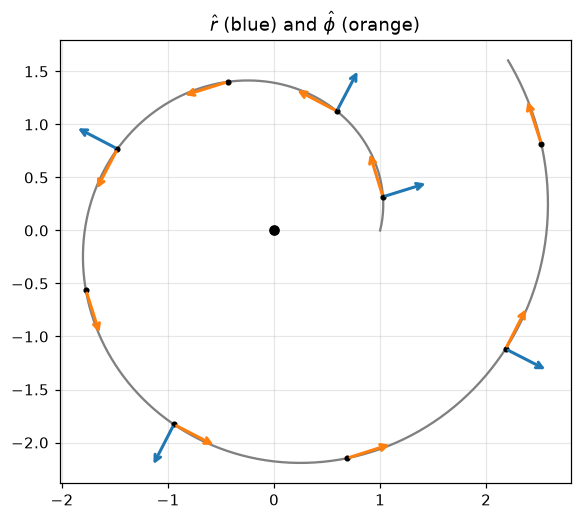

In [5]:
#| label: fig-polar-units
#| caption: The polar unit vectors r̂ (blue) and φ̂ (orange) at several points along a path. Unlike x̂ and ŷ, they point in different directions at different places.
t = np.linspace(0, 2.2 * np.pi, 400)
r = 1 + 0.25 * t
x, y = r * np.cos(t), r * np.sin(t)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x, y, color="gray")
ax.plot(0, 0, "ko")
for tk in np.linspace(0.3, 2.1 * np.pi, 9):
    rk = 1 + 0.25 * tk
    p = rk * np.array([np.cos(tk), np.sin(tk)])
    rh = np.array([np.cos(tk), np.sin(tk)])
    ph = np.array([-np.sin(tk), np.cos(tk)])
    ax.annotate("", xy=p + 0.45 * rh, xytext=p, arrowprops=dict(arrowstyle="->", color="tab:blue", lw=2))
    ax.annotate("", xy=p + 0.45 * ph, xytext=p, arrowprops=dict(arrowstyle="->", color="tab:orange", lw=2))
    ax.plot(*p, "k.", ms=6)
ax.set_aspect("equal")
ax.set_title(r"$\hat{r}$ (blue) and $\hat{\phi}$ (orange)")
plt.show()

### Velocity and acceleration

The position vector is simply $\vec{r} = r\hat{r}$. Differentiate with the product rule and {eq}`eq-unit-derivs`:

$$
\vec{v} = \dot r\,\hat{r} + r\dot\phi\,\hat{\phi} .
$$

Differentiate again:

$$
\vec{a} = \big(\ddot r - r\dot\phi^2\big)\,\hat{r} + \big(r\ddot\phi + 2\dot r\dot\phi\big)\,\hat{\phi} .
$$ (eq-polar-accel)

Each extra term has a meaning:

- $-r\dot\phi^2$ is the **centripetal** acceleration. Even at constant $r$, moving around a circle requires an inward acceleration $v^2/r$.
- $2\dot r\dot\phi$ is the **Coriolis-like** term. A particle that moves outward while rotating must speed up sideways to keep the same angular rate.

So Newton's second law in polar form reads

$$
F_r = m\big(\ddot r - r\dot\phi^2\big), \qquad F_\phi = m\big(r\ddot\phi + 2\dot r\dot\phi\big) .
$$ (eq-newton-polar)

In [6]:
# Derive the polar acceleration from the Cartesian one with sympy
t = sp.symbols("t")
r, phi = sp.Function("r")(t), sp.Function("phi")(t)
pos = sp.Matrix([r * sp.cos(phi), r * sp.sin(phi)])
acc = pos.diff(t, 2)
rhat = sp.Matrix([sp.cos(phi), sp.sin(phi)])
phihat = sp.Matrix([-sp.sin(phi), sp.cos(phi)])
display(Math("a_r = " + sp.latex(sp.simplify(acc.dot(rhat)))))
display(Math(r"a_\phi = " + sp.latex(sp.simplify(acc.dot(phihat)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

:::{important} A useful identity
The $\phi$ component can be written as

$$
r\ddot\phi + 2\dot r\dot\phi = \frac{1}{r}\frac{d}{dt}\big(r^2\dot\phi\big).
$$

So if the force has **no** $\phi$ component (a central force), then $r^2\dot\phi$ is constant. Since $mr^2\dot\phi$ is the angular momentum about the origin, central forces conserve angular momentum. This one line underlies Kepler's second law and the whole central-force chapter at the next rung.
:::

::::{prf:example} Pulling a string through a hole
:label: ex-string-hole

A puck of mass $m$ slides on a frictionless table, tied to a string that runs through a small hole at the origin. Initially the puck circles at radius $r_0$ with angular velocity $\omega_0$. Starting at $t = 0$, someone below the table pulls the string down at constant speed $u$, so $r(t) = r_0 - ut$. Find $\phi(t)$ and the tension.

:::{dropdown} Solution
The only horizontal force is the tension, which points toward the hole, so $F_\phi = 0$ and $r^2\dot\phi = r_0^2\omega_0$:

$$
\dot\phi = \frac{r_0^2\omega_0}{(r_0 - ut)^2} .
$$

Integrating from $\phi(0) = 0$,

$$
\phi(t) = \frac{r_0^2\omega_0}{u}\left[\frac{1}{r_0 - ut} - \frac{1}{r_0}\right] = \frac{r_0\,\omega_0\,t}{r_0 - ut} .
$$

The radial equation with $\ddot r = 0$ gives the tension:

$$
-T = m\big(0 - r\dot\phi^2\big) \quad\Longrightarrow\quad T = m r\dot\phi^2 = \frac{m r_0^4\omega_0^2}{r^3} .
$$

As $r$ shrinks, the puck spins faster and the tension grows as $1/r^3$. The work done by the person pulling goes into the puck's kinetic energy.
:::
::::

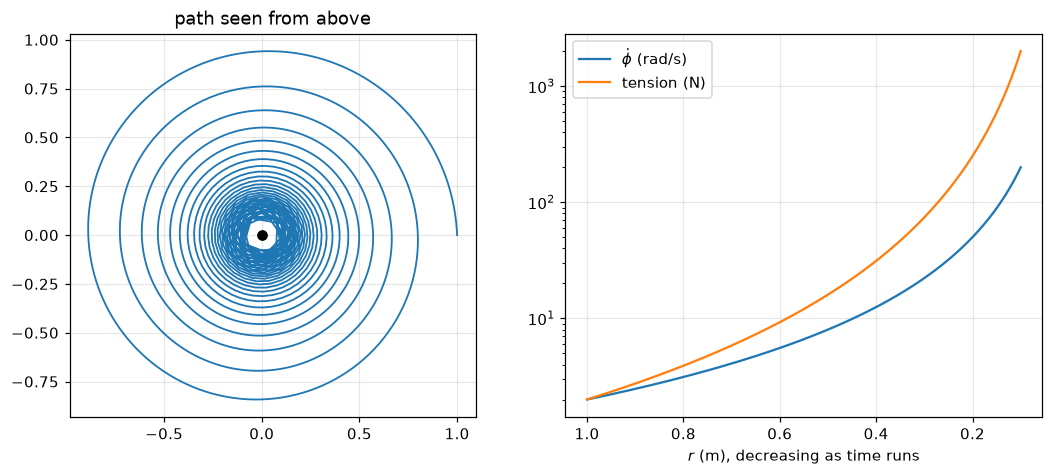

In [7]:
#| label: fig-string-hole
#| caption: Left, the path of the puck as its string is pulled through the hole. Right, the angular velocity and tension both blow up as r shrinks, since r²φ̇ is fixed.
r0, w0, u, m = 1.0, 2.0, 0.08, 0.5
t = np.linspace(0, 0.9 * r0 / u, 1500)
r = r0 - u * t
phi = r0 * w0 * t / r
phidot = r0**2 * w0 / r**2
T = m * r0**4 * w0**2 / r**3

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
axes[0].plot(r * np.cos(phi), r * np.sin(phi), lw=1.2)
axes[0].plot(0, 0, "ko")
axes[0].set_aspect("equal"); axes[0].set_title("path seen from above")

ax = axes[1]
ax.plot(r, phidot, label=r"$\dot\phi$ (rad/s)")
ax.plot(r, T, label="tension (N)")
ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xlabel("$r$ (m), decreasing as time runs"); ax.legend()
plt.tight_layout(); plt.show()

### The pendulum in polar coordinates

Measure $\phi$ from the downward vertical, with the pivot at the origin and $r = L$ fixed. The tension is radial, and gravity has tangential component $-mg\sin\phi$. The $\phi$ equation in {eq}`eq-newton-polar` with $\dot r = 0$ gives

$$
mL\ddot\phi = -mg\sin\phi \qquad\Longrightarrow\qquad \ddot\phi = -\frac{g}{L}\sin\phi .
$$ (eq-pendulum)

The radial equation gives the tension, $T = mg\cos\phi + mL\dot\phi^2$, which is not needed for the motion. For small swings, $\sin\phi\approx\phi$, and the solution is simple harmonic with period $2\pi\sqrt{L/g}$. For large swings, {eq}`eq-pendulum` has no elementary solution, so we integrate it numerically.

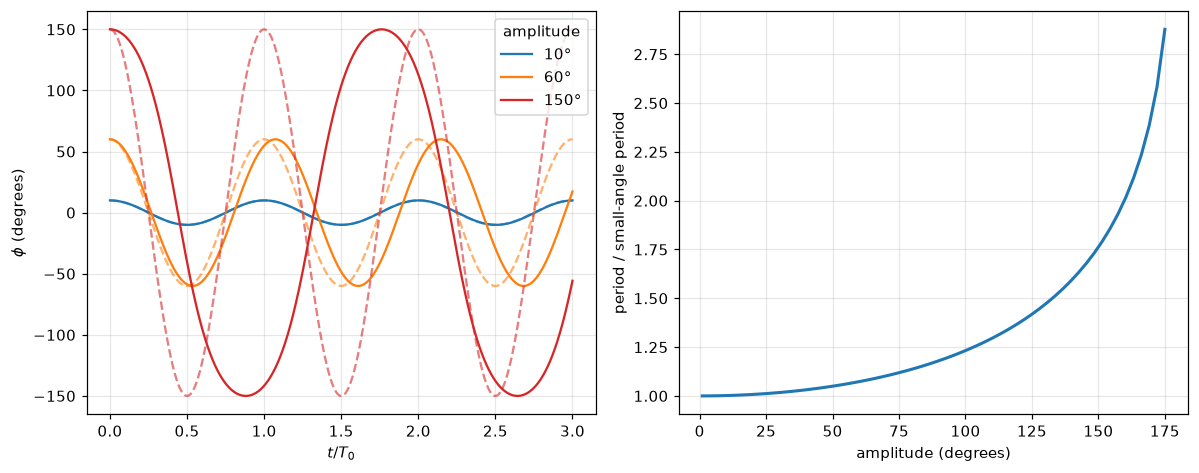

In [8]:
#| label: fig-pendulum
#| caption: Left, the full pendulum (solid) against the small-angle approximation (dashed) for three amplitudes. Right, the true period grows with amplitude and diverges as the release point approaches straight up.
L = 1.0
w0 = np.sqrt(g / L)
T0 = 2 * np.pi / w0
t = np.linspace(0, 3 * T0, 1500)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for amp_deg, c in [(10, "tab:blue"), (60, "tab:orange"), (150, "tab:red")]:
    a = np.radians(amp_deg)
    sol = solve_ivp(lambda t, y: [y[1], -w0**2 * np.sin(y[0])], (0, t[-1]), [a, 0],
                    t_eval=t, rtol=1e-10, atol=1e-12)
    axes[0].plot(t / T0, np.degrees(sol.y[0]), color=c, label=f"{amp_deg}°")
    axes[0].plot(t / T0, amp_deg * np.cos(w0 * t), "--", color=c, alpha=0.6)
axes[0].set_xlabel("$t / T_0$"); axes[0].set_ylabel(r"$\phi$ (degrees)")
axes[0].legend(title="amplitude")

def period(amp):
    # time from release to the first zero crossing is a quarter period
    ev = lambda t, y: y[0]
    ev.terminal, ev.direction = True, -1
    s = solve_ivp(lambda t, y: [y[1], -w0**2 * np.sin(y[0])], (0, 50 * T0), [amp, 0],
                  events=ev, rtol=1e-10, atol=1e-12)
    return 4 * s.t_events[0][0]

amps = np.radians(np.linspace(1, 175, 60))
axes[1].plot(np.degrees(amps), [period(a) / T0 for a in amps], lw=2)
axes[1].set_xlabel("amplitude (degrees)"); axes[1].set_ylabel("period / small-angle period")
plt.tight_layout(); plt.show()

### Exercises

1. A bead moves on a circle of radius $2$ m with $\phi(t) = 3t^2$ (radians, $t$ in seconds). Find the radial and tangential components of its acceleration at $t = 1$ s.
2. A particle moves along the straight line $y = 1$ at constant speed $v$ in the $+x$ direction. In polar coordinates, show that $r^2\dot\phi$ is constant. Why must it be?

:::{dropdown} Hints
1. Use {eq}`eq-polar-accel` with $\dot r = \ddot r = 0$.
2. Write $r^2\dot\phi$ for the particle. Alternatively, think about what force acts on it.
:::

:::{dropdown} Answers
1. $\dot\phi = 6t = 6$ rad/s and $\ddot\phi = 6$ rad/s². So $a_r = -r\dot\phi^2 = -72$ m/s² and $a_\phi = r\ddot\phi = 12$ m/s².
2. With $\tan\phi = 1/x$, differentiating gives $r^2\dot\phi = -\dot x\,y + x\dot y = -v$ (the sign reflects clockwise motion about the origin as $x$ increases). It must be constant because no force acts, and zero force is trivially central, so angular momentum about any point is conserved.
:::

## Velocity-Dependent Forces: Air Resistance

Level 1 problems ignore air. At Level 2 we keep it, and the force on a moving object then depends on its **velocity**. For an object moving through air, the drag force points opposite the velocity and, to a good approximation, has two parts:

$$
\vec{f} = -f(v)\,\hat{v}, \qquad f(v) = bv + cv^2 = f_{\text{lin}} + f_{\text{quad}} .
$$ (eq-drag)

- The **linear** term comes from the fluid's viscosity, the friction of air sliding past the surface. For a sphere of diameter $D$, $b = \beta D$.
- The **quadratic** term comes from the object shoving air out of its way. Its size scales with the cross-sectional area, so $c = \gamma D^2$.

For air near sea level, $\beta \approx 1.6\times 10^{-4}\ \text{N s/m}^2$ and $\gamma\approx 0.25\ \text{N s}^2/\text{m}^4$. The ratio of the two terms decides which one to keep:

$$
\frac{f_{\text{quad}}}{f_{\text{lin}}} = \frac{\gamma D^2 v^2}{\beta D v} = \frac{\gamma}{\beta}\,Dv \approx \big(1.6\times10^{3}\ \text{s/m}^2\big)\,D\,v .
$$ (eq-drag-ratio)

The product $Dv$ is what matters. Large, fast objects feel quadratic drag, and tiny, slow ones feel linear drag. (Fluid dynamicists use the closely related **Reynolds number** $Re = \rho v D/\eta$.)

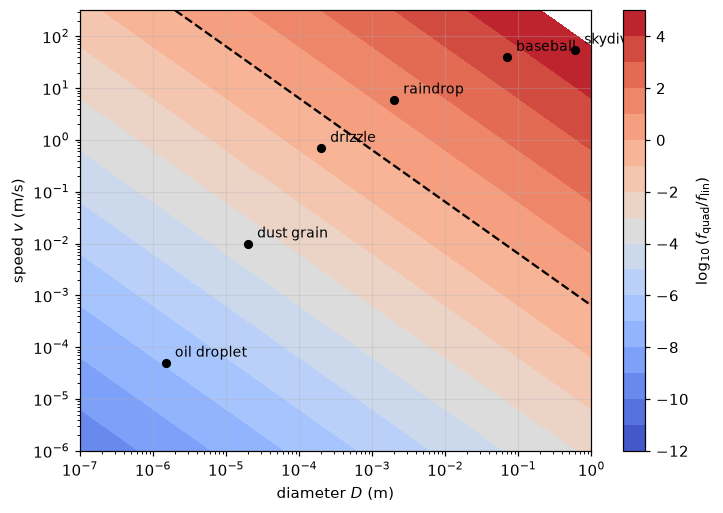

In [9]:
#| label: fig-drag-regimes
#| caption: Ratio of quadratic to linear drag in air as a function of size and speed. Objects far above the dashed line feel essentially pure quadratic drag; objects far below feel pure linear drag.
beta, gamma = 1.6e-4, 0.25
D = np.logspace(-7, 0, 300)
v = np.logspace(-6, 2.5, 300)
DD, VV = np.meshgrid(D, v)
ratio = gamma / beta * DD * VV

fig, ax = plt.subplots(figsize=(7.5, 5.2))
cs = ax.contourf(DD, VV, np.log10(ratio), levels=np.arange(-12, 6, 1), cmap="coolwarm")
ax.contour(DD, VV, ratio, levels=[1], colors="k", linestyles="--")
fig.colorbar(cs, ax=ax, label=r"$\log_{10}(f_{\rm quad}/f_{\rm lin})$")

objects = {"oil droplet": (1.5e-6, 5e-5), "dust grain": (2e-5, 1e-2), "drizzle": (2e-4, 0.7),
           "raindrop": (2e-3, 6.0), "baseball": (0.07, 40), "skydiver": (0.6, 55)}
for name, (d, s) in objects.items():
    ax.plot(d, s, "ko", ms=5)
    ax.annotate(name, (d, s), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("diameter $D$ (m)"); ax.set_ylabel("speed $v$ (m/s)")
plt.show()

:::{note} Why both terms do not appear together in practice
When both terms matter at once, the equation of motion $m\dot v = -bv - cv^2$ is still solvable in one dimension, but in two dimensions it becomes messy. Fortunately, for almost every object {eq}`eq-drag-ratio` is either much larger or much smaller than 1, so one term dominates. The next two sections take each regime in turn.
:::

### Exercises

1. Decide which drag term dominates for (a) a hailstone of diameter 2 cm falling at 15 m/s, and (b) a Millikan oil drop of diameter 1.5 μm drifting at 0.05 mm/s.

:::{dropdown} Hint
Plug into {eq}`eq-drag-ratio` with SI units.
:::

:::{dropdown} Answer
(a) Ratio $\approx 1.6\times10^3 \times 0.02 \times 15 \approx 480$, so quadratic. (b) Ratio $\approx 1.6\times10^3\times1.5\times10^{-6}\times5\times10^{-5}\approx 10^{-7}$, so linear. Millikan's experiment depended on linear (Stokes) drag.
:::

## Linear Drag

With $\vec{f} = -b\vec{v}$ and gravity $m\vec{g}$, the second law is

$$
m\dot{\vec{v}} = m\vec{g} - b\vec{v} .
$$ (eq-linear-drag)

Linear drag has a property that quadratic drag lacks: each component of $\vec{f}$ depends only on the same component of $\vec{v}$. So the $x$ and $y$ equations **uncouple**:

$$
m\dot v_x = -bv_x, \qquad m\dot v_y = -mg - bv_y \quad (y \text{ up}).
$$

Both are first-order linear ODEs in the velocity. The natural time scale is

$$
\tau = \frac{m}{b} .
$$

### Horizontal motion

$\dot v_x = -v_x/\tau$ gives exponential decay:

$$
v_x(t) = v_{x0}\,e^{-t/\tau}, \qquad x(t) = v_{x0}\tau\big(1 - e^{-t/\tau}\big) .
$$

The object never stops in finite time, but it approaches a finite distance $x_\infty = v_{x0}\tau$.

### Vertical motion and terminal velocity

The vertical equation is $\dot v_y = -g - v_y/\tau$. The velocity at which the right side vanishes is the **terminal velocity**:

$$
v_{\text{ter}} = g\tau = \frac{mg}{b} .
$$

Measuring $v_y$ as positive downward, the solution is

$$
v_y(t) = v_{\text{ter}} + \big(v_{y0} - v_{\text{ter}}\big)\,e^{-t/\tau} .
$$ (eq-linear-vertical)

Whatever the starting velocity, even upward, the velocity relaxes exponentially toward $v_{\text{ter}}$ with time constant $\tau$.

In [10]:
# Solve the vertical linear-drag ODE with sympy (down = positive)
t = sp.symbols("t", nonnegative=True)
tau, gg, v0 = sp.symbols("tau g v_0", positive=True)
v = sp.Function("v")
sol = sp.dsolve(sp.Eq(v(t).diff(t), gg - v(t) / tau), v(t), ics={v(0): v0})
display(Math("v(t) = " + sp.latex(sp.simplify(sol.rhs))))

<IPython.core.display.Math object>

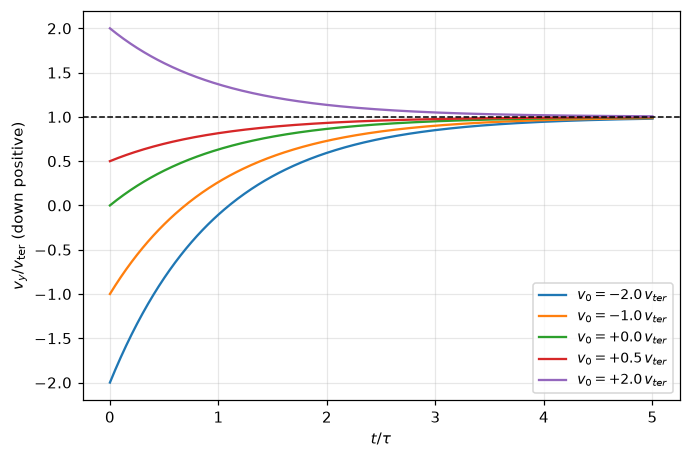

In [11]:
#| label: fig-linear-terminal
#| caption: With linear drag, the vertical velocity relaxes exponentially toward terminal velocity from any starting value, including an upward throw (negative values).
tau = 1.0
vter = g * tau
t = np.linspace(0, 5 * tau, 400)

fig, ax = plt.subplots()
for v0 in [-2 * vter, -vter, 0, 0.5 * vter, 2 * vter]:
    ax.plot(t / tau, (vter + (v0 - vter) * np.exp(-t / tau)) / vter, label=rf"$v_0 = {v0/vter:+.1f}\,v_{{ter}}$")
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel(r"$v_y / v_{\rm ter}$ (down positive)")
ax.legend(fontsize=9); plt.show()

### The full projectile

Putting the two directions together, with $y$ up and launch velocity $\langle v_{x0}, v_{y0}\rangle$ from the origin:

$$
x(t) = v_{x0}\tau\big(1 - e^{-t/\tau}\big), \qquad
y(t) = \big(v_{y0} + v_{\text{ter}}\big)\tau\big(1 - e^{-t/\tau}\big) - v_{\text{ter}}\,t .
$$ (eq-linear-trajectory)

Unlike the vacuum parabola, the trajectory is lopsided. It rises at a shallow angle and comes down steeply, approaching the vertical asymptote $x = v_{x0}\tau$.

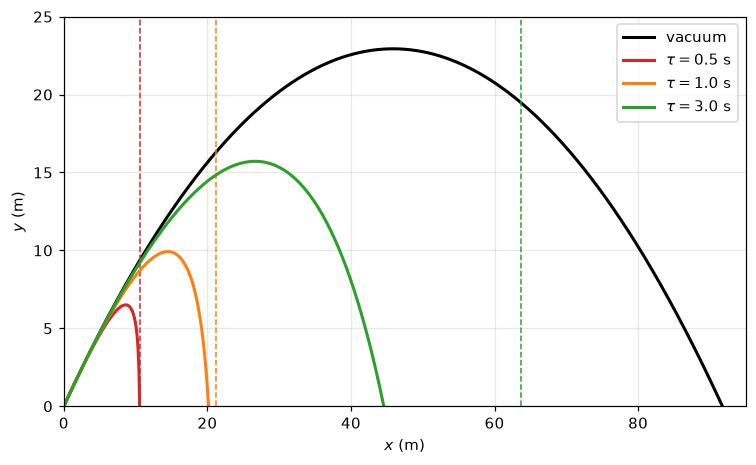

In [12]:
#| label: fig-linear-projectile
#| caption: Projectiles launched at 45° with the same speed and different drag time constants τ. Dashed lines mark each vertical asymptote x = v_x0 τ. As τ grows (less drag) the paths approach the vacuum parabola.
v0, ang = 30.0, np.radians(45)
vx0, vy0 = v0 * np.cos(ang), v0 * np.sin(ang)

fig, ax = plt.subplots(figsize=(8, 4.6))
t = np.linspace(0, 10, 4000)
xv, yv = vx0 * t, vy0 * t - 0.5 * g * t**2
ax.plot(xv[yv >= 0], yv[yv >= 0], "k", lw=2, label="vacuum")
for tau, c in [(0.5, "tab:red"), (1.0, "tab:orange"), (3.0, "tab:green")]:
    vt = g * tau
    x = vx0 * tau * (1 - np.exp(-t / tau))
    y = (vy0 + vt) * tau * (1 - np.exp(-t / tau)) - vt * t
    keep = y >= 0
    ax.plot(x[keep], y[keep], color=c, lw=2, label=rf"$\tau = {tau}$ s")
    ax.axvline(vx0 * tau, color=c, ls="--", lw=1)
ax.set_xlim(0, 95); ax.set_ylim(0, 25)
ax.set_xlabel("$x$ (m)"); ax.set_ylabel("$y$ (m)"); ax.legend()
plt.show()

:::{tip} Checking a drag result
Any drag formula must reduce to the vacuum result when drag disappears, that is, as $\tau\to\infty$. Expand $e^{-t/\tau} \approx 1 - t/\tau + t^2/(2\tau^2)$ in {eq}`eq-linear-trajectory`. You recover $x = v_{x0}t$ and $y = v_{y0}t - \tfrac12 gt^2$. Doing this check by hand is good practice for the perturbation expansions that show up all through Goldstein.
:::

### Exercises

1. Starting from rest, how many time constants does it take a falling object with linear drag to reach 99% of terminal velocity?
2. A ball is thrown straight up at speed $v_0$ with linear drag. Show that its maximum height is
   $y_{\max} = \tau\left[v_0 - v_{\text{ter}}\ln\!\left(1 + \dfrac{v_0}{v_{\text{ter}}}\right)\right]$,
   and check that this reduces to $v_0^2/2g$ when drag is negligible.

:::{dropdown} Hints
1. Set $e^{-t/\tau} = 0.01$ in {eq}`eq-linear-vertical`.
2. With $y$ up, $v_y = (v_0 + v_{\text{ter}})e^{-t/\tau} - v_{\text{ter}}$. Find the time when $v_y = 0$, then use {eq}`eq-linear-trajectory` with $v_{x0} = 0$. For the limit, expand $\ln(1+\epsilon)$ to second order.
:::

:::{dropdown} Answers
1. $t = \tau\ln 100 \approx 4.6\,\tau$.
2. The top is reached at $t_{\text{top}} = \tau\ln(1 + v_0/v_{\text{ter}})$, and substituting gives the stated $y_{\max}$. With $\epsilon = v_0/v_{\text{ter}}\ll1$, $\ln(1+\epsilon)\approx\epsilon - \epsilon^2/2$, so $y_{\max}\approx\tau v_0^2/(2v_{\text{ter}}) = v_0^2/(2g)$.
:::

## Quadratic Drag

For most everyday objects (balls, cars, people) the quadratic term dominates:

$$
m\dot{\vec{v}} = m\vec{g} - c\,v\,\vec{v}, \qquad v = |\vec{v}| = \sqrt{v_x^2 + v_y^2} .
$$ (eq-quad-drag)

The factor $v$ involves both components, so the $x$ and $y$ equations are now **coupled**. In two dimensions there is no closed-form solution, but the one-dimensional cases can be solved exactly.

### Horizontal motion

With only drag acting, $m\dot v = -cv^2$. Separate variables:

$$
\int_{v_0}^{v}\frac{dv'}{v'^2} = -\frac{c}{m}\int_0^t dt' \quad\Longrightarrow\quad v(t) = \frac{v_0}{1 + t/\tau}, \qquad \tau = \frac{m}{cv_0} .
$$

Integrating again,

$$
x(t) = v_0\tau\ln\!\left(1 + \frac{t}{\tau}\right) .
$$

The velocity falls off only as $1/t$, so the distance grows without bound (logarithmically). Quadratic drag weakens as the object slows, so it never fully stops the object. In practice the linear term, which dominates at very low speed, finishes the job.

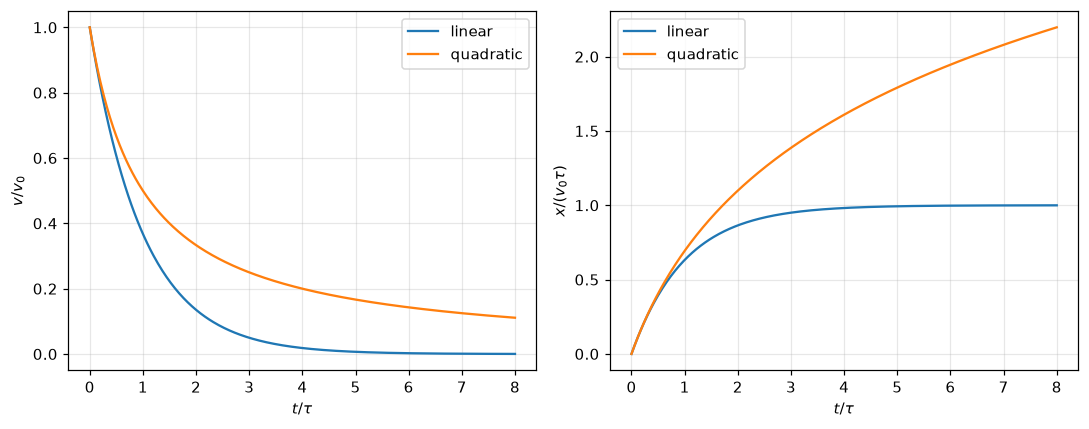

In [13]:
#| label: fig-quad-horizontal
#| caption: Coasting under linear versus quadratic drag, with both forces matched at the starting speed. Quadratic drag bites hard at first but weakens as the object slows, so the object keeps creeping forward.
t = np.linspace(0, 8, 400)
v0, tau = 1.0, 1.0
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(t, v0 * np.exp(-t / tau), label="linear")
axes[0].plot(t, v0 / (1 + t / tau), label="quadratic")
axes[0].set_xlabel(r"$t/\tau$"); axes[0].set_ylabel(r"$v/v_0$"); axes[0].legend()
axes[1].plot(t, v0 * tau * (1 - np.exp(-t / tau)), label="linear")
axes[1].plot(t, v0 * tau * np.log(1 + t / tau), label="quadratic")
axes[1].set_xlabel(r"$t/\tau$"); axes[1].set_ylabel(r"$x/(v_0\tau)$"); axes[1].legend()
plt.tight_layout(); plt.show()

### Vertical motion

For a falling object (down positive), $m\dot v = mg - cv^2$. Terminal velocity is where the right side vanishes:

$$
v_{\text{ter}} = \sqrt{\frac{mg}{c}} .
$$

Dropped from rest, separation of variables and the integral $\int dv/(1 - v^2/v_{\text{ter}}^2) = v_{\text{ter}}\tanh^{-1}(v/v_{\text{ter}})$ give

$$
v(t) = v_{\text{ter}}\tanh\!\left(\frac{gt}{v_{\text{ter}}}\right), \qquad
y(t) = \frac{v_{\text{ter}}^2}{g}\ln\cosh\!\left(\frac{gt}{v_{\text{ter}}}\right) .
$$ (eq-quad-vertical)

For early times $\tanh u\approx u$, so $v\approx gt$, free fall. For late times $\tanh\to1$, so $v\to v_{\text{ter}}$.

In [14]:
# Verify that the tanh solution satisfies m v' = m g - c v^2 and starts at rest
t, gg, vt = sp.symbols("t g v_t", positive=True)
v = vt * sp.tanh(gg * t / vt)
residual = sp.diff(v, t) - gg * (1 - v**2 / vt**2)   # divide the ODE through by m, c/m = g/v_t^2
display(Math(r"\text{residual: } \dot v - g\left(1 - \frac{v^2}{v_t^2}\right) = " + sp.latex(sp.simplify(residual))))
display(Math("v(0) = " + sp.latex(v.subs(t, 0))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Two dimensions: a numerical solution

For a projectile with quadratic drag, write {eq}`eq-quad-drag` as four first-order equations for $(x, y, v_x, v_y)$ and hand them to an ODE solver. This is the standard move at Level 2 whenever a closed form does not exist, and the same code structure handles nearly any force law.

Take a baseball: $m = 0.145$ kg, $D = 7.3$ cm, so $c = \gamma D^2\approx1.3\times10^{-3}$ N·s²/m² and $v_{\text{ter}} = \sqrt{mg/c}\approx 33$ m/s. A strong hit leaves the bat at about 45 m/s, faster than terminal velocity, so drag is a large effect.

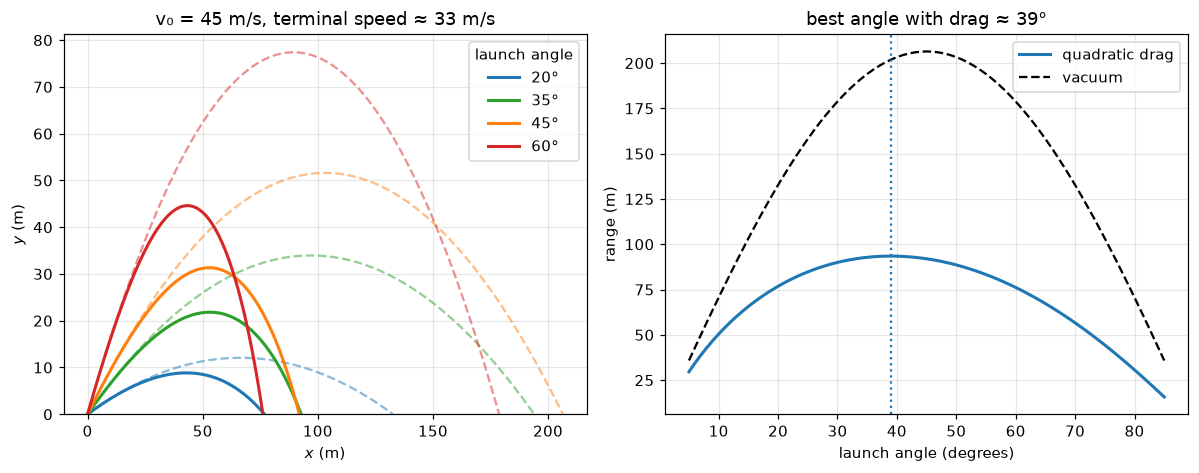

c = 1.332e-03 N s^2/m^2, v_ter = 32.7 m/s, max range with drag = 93.5 m (vacuum: 206.4 m)


In [15]:
#| label: fig-baseball
#| caption: Left, a baseball hit at 45 m/s at several angles, with quadratic drag (solid) and in vacuum (dashed). Right, the range with drag peaks well below 45°.
m, Dball, gamma = 0.145, 0.073, 0.25
c = gamma * Dball**2
vter = np.sqrt(m * g / c)

def rhs(t, s):
    x, y, vx, vy = s
    sp_ = np.hypot(vx, vy)
    return [vx, vy, -(c / m) * sp_ * vx, -g - (c / m) * sp_ * vy]

def land(t, s):
    return s[1]
land.terminal, land.direction = True, -1

def flight(v0, deg):
    a = np.radians(deg)
    return solve_ivp(rhs, (0, 30), [0, 0, v0 * np.cos(a), v0 * np.sin(a)], events=land,
                     max_step=0.01, rtol=1e-8)

v0 = 45.0
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for deg, col in [(20, "tab:blue"), (35, "tab:green"), (45, "tab:orange"), (60, "tab:red")]:
    s = flight(v0, deg)
    axes[0].plot(s.y[0], s.y[1], color=col, lw=2, label=f"{deg}°")
    a = np.radians(deg); T = 2 * v0 * np.sin(a) / g; tt = np.linspace(0, T, 200)
    axes[0].plot(v0 * np.cos(a) * tt, v0 * np.sin(a) * tt - 0.5 * g * tt**2, "--", color=col, alpha=0.5)
axes[0].set_xlabel("$x$ (m)"); axes[0].set_ylabel("$y$ (m)")
axes[0].set_ylim(0, None); axes[0].legend(title="launch angle")
axes[0].set_title(f"v₀ = {v0:.0f} m/s, terminal speed ≈ {vter:.0f} m/s")

angles = np.linspace(5, 85, 81)
ranges = [flight(v0, d).y_events[0][0][0] for d in angles]
best = angles[int(np.argmax(ranges))]
axes[1].plot(angles, ranges, lw=2, label="quadratic drag")
axes[1].plot(angles, v0**2 * np.sin(2 * np.radians(angles)) / g, "k--", label="vacuum")
axes[1].axvline(best, color="tab:blue", ls=":")
axes[1].set_xlabel("launch angle (degrees)"); axes[1].set_ylabel("range (m)")
axes[1].set_title(f"best angle with drag ≈ {best:.0f}°"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"c = {c:.3e} N s^2/m^2, v_ter = {vter:.1f} m/s, max range with drag = {max(ranges):.1f} m "
      f"(vacuum: {v0**2/g:.1f} m)")

:::{note} Real baseballs
A real baseball's drag coefficient changes with speed, and spin adds a lift force (the Magnus effect) that a backspin fly ball uses to travel farther. The model here gets the main story right: drag cuts the range roughly in half and pushes the optimal angle well below 45°.
:::

### Exercises

1. A ball is thrown straight up at speed $v_0$ with quadratic drag. Show that it reaches the top after $t = \dfrac{v_{\text{ter}}}{g}\arctan\!\left(\dfrac{v_0}{v_{\text{ter}}}\right)$.
2. Show that the maximum height is $y_{\max} = \dfrac{v_{\text{ter}}^2}{2g}\ln\!\left(1 + \dfrac{v_0^2}{v_{\text{ter}}^2}\right)$.

:::{dropdown} Hints
1. On the way up, both gravity and drag point down: $m\dot v = -mg - cv^2$. Separate variables.
2. Use the chain rule to write $\dot v = v\,dv/dy$, then separate $v$ and $y$.
:::

:::{dropdown} Answers
1. $\dot v = -g(1 + v^2/v_{\text{ter}}^2)$. Then $\int_{v_0}^{0} dv/(1 + v^2/v_{\text{ter}}^2) = -gt$, which gives $v_{\text{ter}}\arctan(v_0/v_{\text{ter}}) = gt$.
2. $v\,dv/(1 + v^2/v_{\text{ter}}^2) = -g\,dy$. The left side integrates to $\tfrac{v_{\text{ter}}^2}{2}\ln(1 + v^2/v_{\text{ter}}^2)$, which gives the result. For small $v_0/v_{\text{ter}}$ it reduces to $v_0^2/2g$.
:::

## A Magnetic Force: Complex Numbers to the Rescue

Air resistance is not the only velocity-dependent force. A charge $q$ moving through a magnetic field feels

$$
\vec{F} = q\,\vec{v}\times\vec{B} .
$$

This force is always perpendicular to $\vec{v}$, so it does no work and the speed never changes. Take $\vec{B} = B\hat{z}$. Then

$$
m\dot v_x = qBv_y, \qquad m\dot v_y = -qBv_x, \qquad m\dot v_z = 0 .
$$

The $z$ motion is uniform. The $x$ and $y$ equations are coupled, with the **cyclotron frequency** $\omega = qB/m$:

$$
\dot v_x = \omega v_y, \qquad \dot v_y = -\omega v_x .
$$

### The complex-number trick

Combine the two components into one complex number, $\eta = v_x + iv_y$. Then

$$
\dot\eta = \dot v_x + i\dot v_y = \omega v_y - i\omega v_x = -i\omega(v_x + iv_y) = -i\omega\eta .
$$

Two coupled real equations have become one complex equation, with solution $\eta(t) = \eta_0 e^{-i\omega t}$. Since $|\eta| = |\eta_0|$ is constant, the speed in the $xy$-plane is constant, and the velocity vector rotates clockwise at rate $\omega$. Integrating once more shows the particle moves on a circle of radius

$$
R = \frac{v_\perp}{\omega} = \frac{mv_\perp}{qB} .
$$

Adding the uniform $z$ motion turns the circle into a **helix**. Charged particles spiral along magnetic field lines this way in the solar wind, in the Earth's radiation belts, and in astrophysical plasmas.

:::{tip} Why the trick is worth learning
Complex exponentials turn linear systems of ODEs into algebra. The same move solves damped and driven oscillators, AC circuits, wave equations and quantum mechanics. Goldstein's small-oscillation chapter is this idea at full strength.
:::

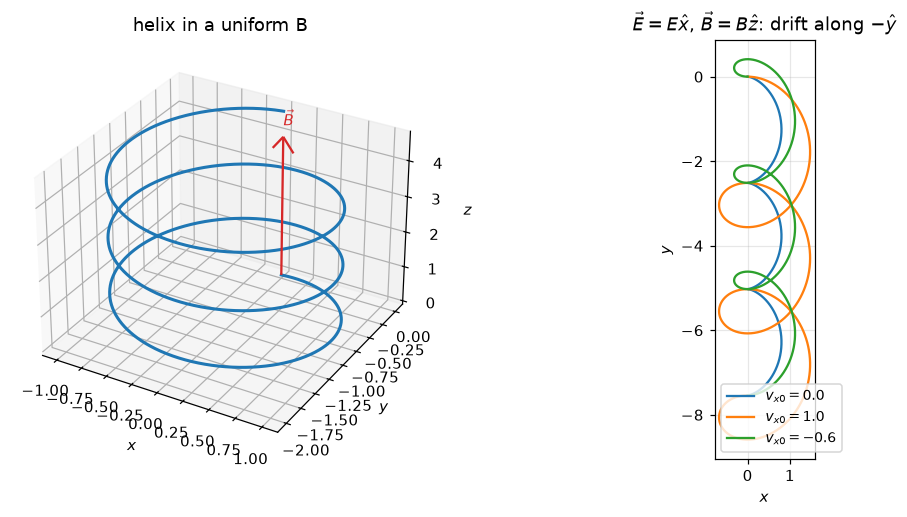

In [16]:
#| label: fig-helix
#| caption: Left, a charge in a uniform magnetic field along z spirals along a helix. Right, adding an electric field perpendicular to B produces a sideways drift at speed E/B (the E×B drift), independent of the charge.
q, mass, B = 1.0, 1.0, 1.0
w = q * B / mass
t = np.linspace(0, 6 * np.pi, 2000)

fig = plt.figure(figsize=(11, 4.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
v_perp, v_par = 1.0, 0.25
eta = v_perp * np.exp(-1j * w * t)                  # complex velocity v_x + i v_y
pos = (eta - v_perp) / (-1j * w)                    # integrate, starting at the origin
ax.plot(pos.real, pos.imag, v_par * t, lw=2)
ax.quiver(0, 0, 0, 0, 0, 4, color="tab:red", arrow_length_ratio=0.1)
ax.text(0, 0, 4.3, r"$\vec{B}$", color="tab:red")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$z$")
ax.set_title("helix in a uniform B")

ax2 = fig.add_subplot(1, 2, 2)
E = 0.4
def rhs(t, s):
    x, y, vx, vy = s
    return [vx, vy, (q / mass) * (E + vy * B), (q / mass) * (-vx * B)]
for vx0, col in [(0.0, "tab:blue"), (1.0, "tab:orange"), (-0.6, "tab:green")]:
    s = solve_ivp(rhs, (0, t[-1]), [0, 0, vx0, 0], t_eval=t, rtol=1e-9)
    ax2.plot(s.y[0], s.y[1], color=col, label=f"$v_{{x0}} = {vx0}$")
ax2.set_aspect("equal"); ax2.set_xlabel("$x$"); ax2.set_ylabel("$y$")
ax2.set_title(r"$\vec{E} = E\hat{x}$, $\vec{B} = B\hat{z}$: drift along $-\hat{y}$")
ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

### Exercises

1. A proton ($m = 1.67\times10^{-27}$ kg, $q = 1.60\times10^{-19}$ C) moves at $1.0\times10^6$ m/s perpendicular to a $1.0$ T field. Find $\omega$ and the radius of its circle.
2. Show directly from $\vec{F} = q\vec{v}\times\vec{B}$ that the kinetic energy is constant.

:::{dropdown} Hints
1. $\omega = qB/m$ and $R = v/\omega$.
2. Compute $\frac{d}{dt}\left(\tfrac12 m v^2\right) = \vec{F}\cdot\vec{v}$.
:::

:::{dropdown} Answers
1. $\omega\approx9.6\times10^7$ rad/s and $R\approx1.0$ cm.
2. $\vec{F}\cdot\vec{v} = q(\vec{v}\times\vec{B})\cdot\vec{v} = 0$, because $\vec{v}\times\vec{B}$ is perpendicular to $\vec{v}$.
:::

## Climbing the Ladder

The mapping's example ladder for this topic is **block on an incline → projectile with drag → bead on a rotating hoop**. Here is what changes at each rung. The physics is always $\vec{F} = m\vec{a}$, and only the technique grows.

:::{list-table} One topic, three rungs
:header-rows: 1
:label: tbl-ladder

* - Rung
  - Problem
  - What you must do
* - Level 1
  - A block slides down a frictionless 30° incline from rest. How fast is it moving after 2 m?
  - Draw a free-body diagram, find a constant acceleration $g\sin30^\circ$, use a kinematics formula. Answer: about $4.4$ m/s.
* - Level 2
  - A projectile with linear or quadratic drag
  - Write the second law as an ODE, solve it in general (analytically or numerically), check limits.
* - Level 3
  - A bead slides on a frictionless circular hoop of radius $R$ that spins about its vertical diameter at angular velocity $\omega$. Find the equilibrium positions and their stability.
  - Eliminate the unknown constraint force by choosing a generalized coordinate (the angle on the hoop), derive one equation of motion, and analyze equilibria.
:::

### A preview of the Level 3 rung

Using the polar angle $\theta$ of the bead measured from the bottom of the hoop, the equation of motion that comes out of the Level 3 machinery is

$$
\ddot\theta = \left(\omega^2\cos\theta - \frac{g}{R}\right)\sin\theta .
$$

You can get it at Level 2 too, by writing Newton's law in the rotating hoop's frame and tracking the normal force, but it takes noticeably more work. That extra work is the argument for Lagrangian mechanics.

The interesting physics: the bottom ($\theta = 0$) is stable only when $\omega^2 < g/R$. Above that critical spin rate, the bottom becomes unstable and two new stable equilibria appear at $\cos\theta_0 = g/(R\omega^2)$. This is a **pitchfork bifurcation**, a simple example of symmetry breaking.

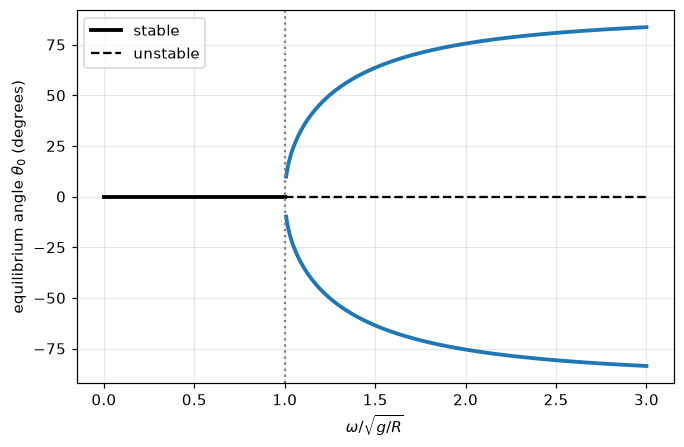

In [17]:
#| label: fig-bead-hoop
#| caption: Equilibrium angles of a bead on a spinning hoop. Below the critical spin rate only the bottom is stable; above it the bottom turns unstable (dashed) and the bead settles at ±θ₀.
gR = 1.0                       # g/R in units where the critical omega is 1
w = np.linspace(0, 3, 400)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(w[w <= 1], 0 * w[w <= 1], "k", lw=2.5, label="stable")
ax.plot(w[w >= 1], 0 * w[w >= 1], "k--", lw=1.5, label="unstable")
wb = w[w > 1]
th = np.degrees(np.arccos(gR / wb**2))
ax.plot(wb, th, "tab:blue", lw=2.5)
ax.plot(wb, -th, "tab:blue", lw=2.5)
ax.axvline(1, color="gray", ls=":")
ax.set_xlabel(r"$\omega / \sqrt{g/R}$"); ax.set_ylabel(r"equilibrium angle $\theta_0$ (degrees)")
ax.legend(); plt.show()

:::{tip} For the Problem Log
A complete trio for this row would be: one constant-force Tipler problem, one drag problem you solve as an ODE (analytic for linear, numeric for quadratic), and the bead-on-hoop problem done with a Lagrangian. Log the technique each level added, matching the "technique" columns in your mapping workbook.
:::

## Summary

- Newton's laws hold in **inertial frames**. The first law is what identifies those frames.
- The second law, $\vec{F} = \dot{\vec{p}}$, is a **second-order differential equation**. A solution needs initial position and velocity.
- The third law makes internal forces cancel, so total momentum changes only through external forces, and the center of mass moves like a single particle.
- In Cartesian coordinates the components separate. In **polar coordinates** the moving unit vectors add the centripetal ($-r\dot\phi^2$) and Coriolis-like ($2\dot r\dot\phi$) terms, and central forces conserve $r^2\dot\phi$.
- **Air resistance** has a linear part ($\propto Dv$) and a quadratic part ($\propto D^2v^2$). The ratio $\approx 1.6\times10^3\,Dv$ in SI units picks the regime.
  - Linear drag uncouples the components and gives exponential approach to $v_{\text{ter}} = mg/b$.
  - Quadratic drag couples them. One-dimensional cases give $1/t$ and $\tanh$ solutions; two-dimensional motion needs numerical integration.
- Complex variables turn the coupled magnetic-force equations into $\dot\eta = -i\omega\eta$, giving circles and helices.

## Appendix: MyST patterns used here

These notes use the same MyST conventions as the vector calculus notebook. Two additions are worth copying:

**Exercises with separate hint and answer dropdowns:**
````md
### Exercises

1. Question text.

:::{dropdown} Hints
1. Hint text.
:::

:::{dropdown} Answers
1. Answer text.
:::
````

**A table inside an admonition.** Pipe tables work inside directives, which is how the ladder summary at the top is built:
````md
:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca | ... |
:::
````